In [2]:
import os
import sys
from pathlib import Path

DIRPATH_REPO = Path().resolve().parents[0]
sys.path.append(str(DIRPATH_REPO))
print(DIRPATH_REPO)

import matplotlib.pyplot as plt
import numpy as np

from rate_model import RateModelLin

#ARTIFACT_DIR = Path(__file__).resolve().parent / 'artifacts' / 'rate_model_ker'
#ARTIFACT_PATH = ARTIFACT_DIR / 'rate_model_kernel_syn_demo.png'

/home/nnovikov/repo/resp_predictor


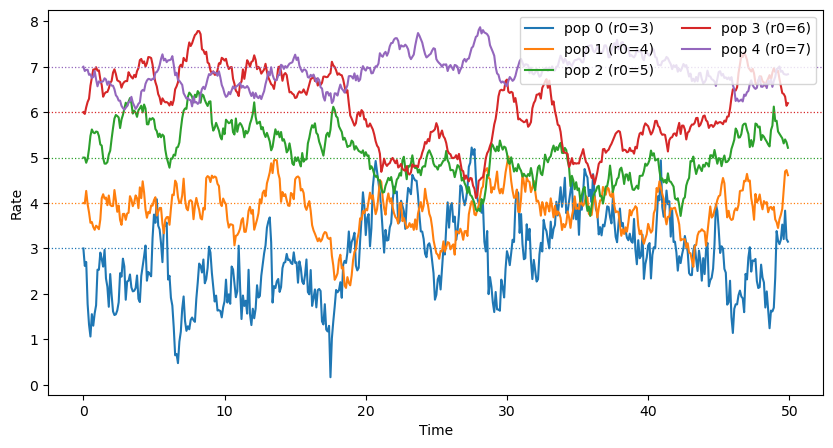

In [3]:
#np.random.seed(123)

# Target operating point
r0 = np.array([3, 4, 5, 6, 7]).reshape(-1, 1)
n_pop = r0.shape[0]

# Model parameters
tau = np.linspace(0.4, 1.8, n_pop).reshape(-1, 1)

# Create model
model, h0, J = RateModelLin.from_steady_state(
    r0=r0,
    tau=tau,
    R=0.8
)

# Simulation params
T = 50
dt = 0.1
nsteps = int(T / dt)

# Add input noise
sigma_h = 0.5
H = h0 + sigma_h * np.random.randn(n_pop, nsteps) / np.sqrt(dt)

# Run model
rr = model.run(H, r0, dt=dt, nsteps=nsteps)

fig, ax = plt.subplots(1, 1, figsize=(10, 5))
for pop in range(n_pop):
    ax.plot(rr.time, rr.isel(pop=pop), label=f'pop {pop} (r0={r0[pop, 0]:.0f})')
    ax.axhline(r0[pop, 0], color=f'C{pop}', linestyle=':', linewidth=0.9)

ax.set_xlabel('Time')
ax.set_ylabel('Rate')
ax.legend(loc='upper right', ncol=2)
